<a href="https://colab.research.google.com/github/jishnujs1990/Study/blob/master/RevenueVision_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import packages

In [1]:
import importlib.util
import subprocess
import sys

packages = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'seaborn': 'seaborn', 'sklearn': 'scikit-learn', 'joblib': 'joblib',
    'xgboost': 'xgboost', 'statsmodels': 'statsmodels'
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch',
                           '--index-url', 'https://download.pytorch.org/whl/cpu'])
print('Packages are available.')

Packages are available.


In [2]:
from pathlib import Path
import re, json, sqlite3, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
from torch import nn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from statsmodels.tsa.arima.model import ARIMA
from IPython.display import display, Markdown

SEED = 42
HORIZON = 4     # Predict the next four supplied buckets
LOOKBACK = 26   # Read the last 26 buckets
SEASON = 53     # Supplied dataset convention, not ISO weeks
EARLIEST_ORIGIN = SEASON + 13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

## 2. Read your CSV

In [9]:
input_path = "/content/Global_Superstore_Estimated_Dates.csv"
CSV_ENCODING = 'utf-8-sig'

# Read the CSV file
raw = pd.read_csv(input_path, encoding=CSV_ENCODING)

# Print summary and display data
print(f'Loaded {len(raw):,} rows and {len(raw.columns)} columns')

display(raw.head())

Loaded 51,290 rows and 32 columns


,Category,City,Country,Customer ID,Customer Name,Discount,Market,ji_lu-shu,Order Date,Order ID,Order Priority,Product ID,Product Name,Profit,Quantity,Region,Row ID,Sales,Segment,Ship Date,Ship Mode,Shipping Cost,State,Sub-Category,Year,Market2,weeknum,Original Order Date,Original Ship Date,Dates Are Synthetic,Order Date Method,Ship Date Method
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,Second Class,4.37,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,Standard Class,1.81,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,Standard Class,4.59,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,Standard Class,1.32,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay


## 3. Inspect the input
One row is a transaction **line**, not necessarily one order. Check types, missing values,
exact duplicates, and sample values before cleaning.

In [10]:
raw.info()
display(pd.DataFrame({'type': raw.dtypes.astype(str),
                      'missing': raw.isna().sum(),
                      'unique_values': raw.nunique()}))
print('Exact duplicate rows:', raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Category             51290 non-null  object 
 1   City                 51290 non-null  object 
 2   Country              51290 non-null  object 
 3   Customer ID          51290 non-null  object 
 4   Customer Name        51290 non-null  object 
 5   Discount             51290 non-null  float64
 6   Market               51290 non-null  object 
 7   ji_lu-shu            51290 non-null  int64  
 8   Order Date           51290 non-null  object 
 9   Order ID             51290 non-null  object 
 10  Order Priority       51290 non-null  object 
 11  Product ID           51290 non-null  object 
 12  Product Name         51290 non-null  object 
 13  Profit               51290 non-null  float64
 14  Quantity             51290 non-null  int64  
 15  Region               51290 non-null 

,type,missing,unique_values
Category,object,0,3
City,object,0,3636
Country,object,0,147
Customer ID,object,0,4873
Customer Name,object,0,795
Discount,float64,0,27
Market,object,0,7
ji_lu-shu,int64,0,1
Order Date,object,0,212
Order ID,object,0,25035


Exact duplicate rows: 0


## 4. Clean and validate

In [11]:
# Step 1: Create a copy of the original data
df = raw.copy()

# Step 2: Clean column names
# Example: "Customer Name" becomes "customer_name"
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Step 3: Remove duplicate rows
df = df.drop_duplicates()

# Step 4: Convert columns to numeric format
numeric_cols = ['sales', 'profit', 'quantity', 'discount',
                'shipping_cost', 'year', 'weeknum']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Step 5: Fill missing numeric values
df['discount'] = df['discount'].fillna(0)
df['shipping_cost'] = df['shipping_cost'].fillna(df['shipping_cost'].median())

# Step 6: Remove rows with missing important values
df = df.dropna(subset=['sales', 'profit', 'quantity', 'year', 'weeknum'])

# Step 7: Remove invalid sales and quantity records
df = df[(df['sales'] >= 0) & (df['quantity'] > 0)]

# Step 8: Fill missing text values
df = df.fillna('Unknown')

# Step 9: Display cleaned data
print("Total cleaned rows:", len(df))
df.head()

Total cleaned rows: 51290


,category,city,country,customer_id,customer_name,discount,market,ji_lu-shu,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,row_id,sales,segment,ship_date,ship_mode,shipping_cost,state,sub-category,year,market2,weeknum,original_order_date,original_ship_date,dates_are_synthetic,order_date_method,ship_date_method
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,Second Class,4.37,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,Standard Class,1.81,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,Standard Class,4.59,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,Standard Class,1.32,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay


## 5. Create the approved estimated dates

In [29]:
# Step 1: Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Step 2: Convert existing dates into datetime format
df['order_date'] = pd.to_datetime(df['order_date'])
df['ship_date'] = pd.to_datetime(df['ship_date'])

# Step 3: Extract month and quarter for analysis
df['month'] = df['order_date'].dt.month
df['quarter'] = df['order_date'].dt.quarter
# Calculate and store df['estimated_month'] for the following steps.
df['estimated_month'] = df.order_date.dt.strftime('%Y-%m')
# Calculate and store df['estimated_quarter'] for the following steps.
df['estimated_quarter'] = df.order_date.dt.quarter


# Step 4: Check the result
df[['order_date', 'ship_date', 'year', 'weeknum', 'month', 'quarter']].head()

,order_date,ship_date,year,weeknum,month,quarter
0,2011-01-08,2011-01-12,2011,2,1,1
1,2011-01-22,2011-01-26,2011,4,1,1
2,2011-08-06,2011-08-10,2011,32,8,3
3,2011-08-06,2011-08-10,2011,32,8,3
4,2011-10-01,2011-10-05,2011,40,10,4


## 6. Keys, outlier flags, and category encoding
Raw Order IDs are reused. We count composite orders using Order ID + Customer ID + Country + Year + bucket.
Product keys also include Product Name. IQR outliers are **flagged and retained**.
Category codes are descriptive labels, not ordered numerical inputs to the revenue forecast.

In [30]:
order_cols = ['order_id', 'customer_id', 'country', 'year', 'weeknum']
df['order_key'] = df[order_cols].astype(str).agg('|'.join, axis=1)
df['product_key'] = df[['product_id', 'product_name']].astype(str).agg('|'.join, axis=1)
q1, q3 = df.sales.quantile([0.25, 0.75])
iqr = q3 - q1
df['sales_iqr_outlier'] = (df.sales < q1 - 1.5*iqr) | (df.sales > q3 + 1.5*iqr)
df['log1p_sales'] = np.log1p(df.sales)
df['profit_margin'] = df.profit.div(df.sales.where(df.sales > 0))
encoder = LabelEncoder()
df['category_code'] = encoder.fit_transform(df.category)
quality = {
    'input_rows': len(raw), 'clean_rows': len(df),
    'outliers_retained': int(df.sales_iqr_outlier.sum()),
    'negative_profit_lines': int((df.profit < 0).sum()),
    'zero_sales_lines': int((df.sales == 0).sum()),
    'reused_order_ids': int((df.groupby('order_id').order_key.nunique() > 1).sum()),
    'dates_are_synthetic': True
}
display(pd.Series(quality))
print('Category labels:', dict(enumerate(encoder.classes_)))
display(df[['sales', 'profit', 'quantity', 'discount', 'shipping_cost']].describe())

,0
input_rows,51290
clean_rows,51290
outliers_retained,5655
negative_profit_lines,12544
zero_sales_lines,1
reused_order_ids,660
dates_are_synthetic,True


Category labels: {0: 'Furniture', 1: 'Office Supplies', 2: 'Technology'}


,sales,profit,quantity,discount,shipping_cost
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.498440,28.610982,3.476545,0.142908,26.375818
std,487.567175,174.340972,2.278766,0.212280,57.296810
min,0.000000,-6599.978000,1.000000,0.000000,0.002000
25%,31.000000,0.000000,2.000000,0.000000,2.610000
50%,85.000000,9.240000,3.000000,0.000000,7.790000
75%,251.000000,36.810000,5.000000,0.200000,24.450000
max,22638.000000,8399.976000,14.000000,0.850000,933.570000


## 7. Aggregate into the forecasting series
Group transaction lines into total revenue per Year/weeknum bucket.
For this project we require all 212 supplied buckets from 2011–2014; missing buckets are not silently treated as zero.
The 53-bucket seasonal convention has irregular calendar spacing at year boundaries.

In [31]:
weekly = (df.groupby(['year', 'weeknum'], as_index=False)
          .agg(sales=('sales', 'sum'), profit=('profit', 'sum'),
               quantity=('quantity', 'sum'), order_count=('order_key', 'nunique'),
               estimated_date=('order_date', 'min'))
          .sort_values(['year', 'weeknum']).reset_index(drop=True))
weekly['period_index'] = np.arange(len(weekly))
expected = [(year, week) for year in range(2011, 2015) for week in range(1, 54)]
observed = list(weekly[['year', 'weeknum']].itertuples(index=False, name=None))
if observed != expected:
    raise ValueError('This notebook expects the complete 2011–2014, 53-bucket-per-year file. '
                     'Review missing/extra buckets before changing the evaluation design.')
y = weekly.sales.to_numpy(dtype=float)
assert np.isclose(y.sum(), df.sales.sum())
print(f'{len(df):,} lines become {len(weekly)} forecasting periods.')
display(weekly.head())

51,290 lines become 212 forecasting periods.


,year,weeknum,sales,profit,quantity,order_count,estimated_date,period_index
0,2011,1,808,198.87300,19,4,2011-01-01,0
1,2011,2,25329,2872.82744,262,49,2011-01-08,1
2,2011,3,27840,2678.94898,410,53,2011-01-15,2
3,2011,4,19783,2967.36194,313,46,2011-01-22,3
4,2011,5,17044,-1024.28260,364,53,2011-01-29,4


## 8. Calculate business KPIs
Revenue = sum of line Sales. Do not multiply Sales by Quantity again.
Average order value uses composite **orders**, not transaction-line count.
Overall margin = total Profit / total Sales.

In [32]:
total_sales = float(df.sales.sum())
if total_sales <= 0:
    raise ValueError('Positive total revenue is required for the ratio analyses.')
kpis = {
    'Revenue': total_sales,
    'Profit': float(df.profit.sum()),
    'Profit margin (%)': float(df.profit.sum() / total_sales * 100),
    'Orders': int(df.order_key.nunique()),
    'Average order value': total_sales / df.order_key.nunique(),
    'Customers': int(df.customer_id.nunique()),
    'Quantity': int(df.quantity.sum())
}
display(pd.Series(kpis).to_frame('Value'))
annual = df.groupby('year').agg(revenue=('sales', 'sum'), profit=('profit', 'sum'))
annual['growth_pct'] = annual.revenue.pct_change() * 100
category = df.groupby('category').agg(revenue=('sales', 'sum'), profit=('profit', 'sum'))
regions = df.groupby('region').sales.sum().sort_values(ascending=False)
display(annual)
display(category)

,Value
Revenue,1.264290e+07
Profit,1.467457e+06
Profit margin (%),1.160696e+01
Orders,2.575400e+04
Average order value,4.909103e+02
Customers,4.873000e+03
Quantity,1.783120e+05


,revenue,profit,growth_pct
year,,,
2011,2259511,248940.81154,NaN
2012,2677493,307415.27910,18.498781
2013,3405860,406935.23018,27.203320
2014,4300041,504165.97046,26.254191


,revenue,profit
category,,
Furniture,4110884,285204.72380
Office Supplies,3787330,518473.83430
Technology,4744691,663778.73318


## 9. Explore distributions and relationships
These charts run directly on the cleaned data. High-value Sales are preserved.
The scatter uses a reproducible sample for readability; correlations use all lines.
Correlation describes association and does not establish cause.

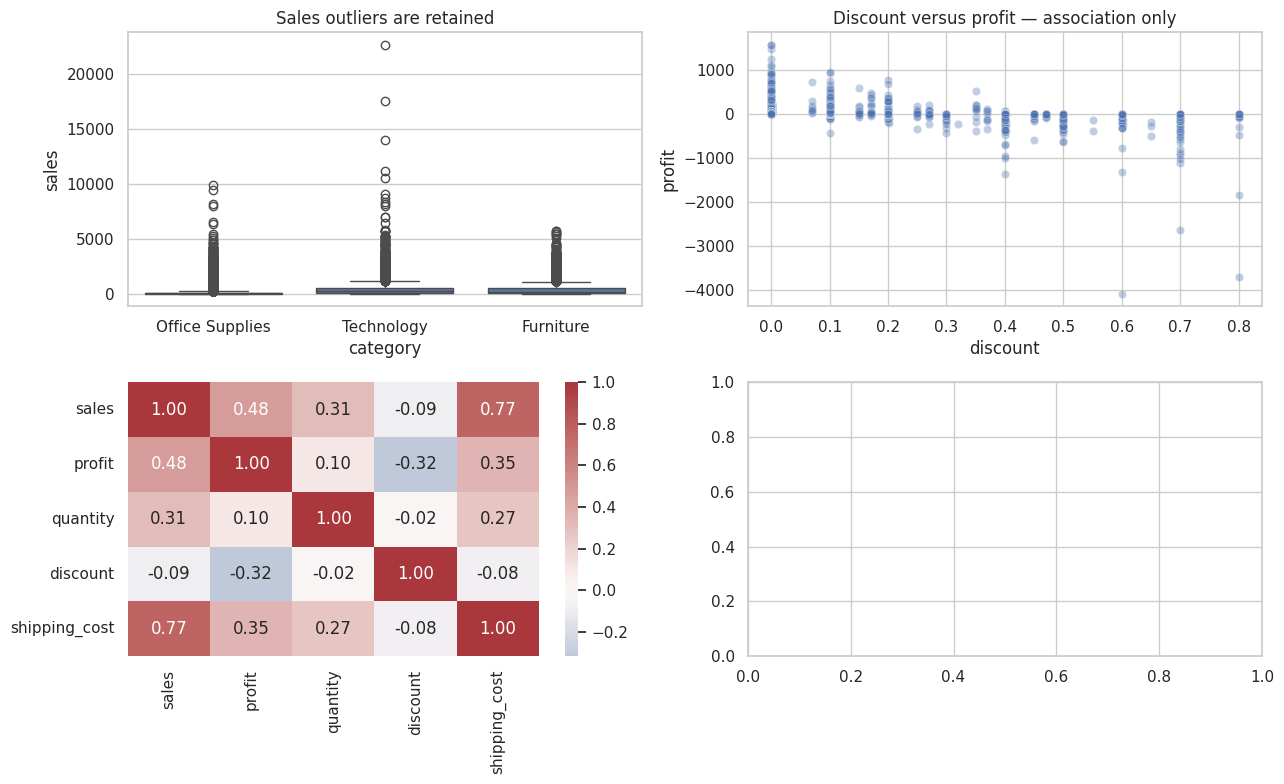

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.boxplot(data=df, x='category', y='sales', ax=axes[0, 0])
axes[0, 0].set_title('Sales outliers are retained')
sample = df.sample(min(3000, len(df)), random_state=SEED)
sns.scatterplot(data=sample, x='discount', y='profit', alpha=0.35, ax=axes[0, 1])
axes[0,1].set_title('Discount versus profit — association only')
correlation = df[['sales', 'profit', 'quantity', 'discount', 'shipping_cost']].corr()
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[1, 0])
fig.tight_layout()
eda_figure = fig
plt.show()

In [35]:
df

,category,city,country,customer_id,customer_name,discount,market,ji_lu-shu,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,row_id,sales,segment,ship_date,...,state,sub-category,year,market2,weeknum,original_order_date,original_ship_date,dates_are_synthetic,order_date_method,ship_date_method,month,quarter,order_key,product_key,sales_iqr_outlier,log1p_sales,profit_margin,category_code,estimated_month,estimated_quarter
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,...,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,1,1,CA-2011-130813|LS-172304|United States|2011|2,OFF-PA-10002005|Xerox 225,False,2.995732,0.491116,1,2011-01,1
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,...,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,1,1,CA-2011-148614|MV-174854|United States|2011|4,"OFF-PA-10002893|Wirebound Service Call Books, ...",False,2.995732,0.489095,1,2011-01,1
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,8,3,CA-2011-118962|CS-121304|United States|2011|32,"OFF-PA-10000659|Adams Phone Message Book, Prof...",False,3.091042,0.468657,1,2011-08,3
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,8,3,CA-2011-118962|CS-121304|United States|2011|32,OFF-PA-10001144|Xerox 1913,False,4.718499,0.479827,1,2011-08,3
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,...,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,10,4,CA-2011-146969|AP-109154|United States|2011|40,OFF-PA-10002105|Xerox 223,False,1.945910,0.518400,1,2011-10,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51285,Office Supplies,Los Angeles,United States,AM-103604,Alice McCarthy,0.2,US,1,2014-12-03,CA-2014-109701,High,OFF-BI-10000632,Satellite Sectional Post Binders,22.5732,2,West,33646,69,Corporate,2014-12-07,...,California,Binders,2014,North America,49,2014-12-03,2014-12-07,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,12,4,CA-2014-109701|AM-103604|United States|2014|49,OFF-BI-10000632|Satellite Sectional Post Binders,False,4.248495,0.327148,1,2014-12,4
51286,Office Supplies,Los Angeles,United States,AM-103604,Alice McCarthy,0.2,US,1,2014-12-03,CA-2014-109701,High,OFF-BI-10004187,Staples,3.1584,6,West,33645,9,Corporate,2014-12-07,...,California,Binders,2014,North America,49,2014-12-03,2014-12-07,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,12,4,CA-2014-109701|AM-103604|United States|2014|49,OFF-BI-10004187|Staples,False,2.302585,0.350933,1,2014-12,4
51

## 10. Explore annual and supplied-bucket trends
Annual category totals use the observed Year field. The bucket plot shows supplied ordering.
The monthly plot uses estimated dates and cannot verify real monthly seasonality.

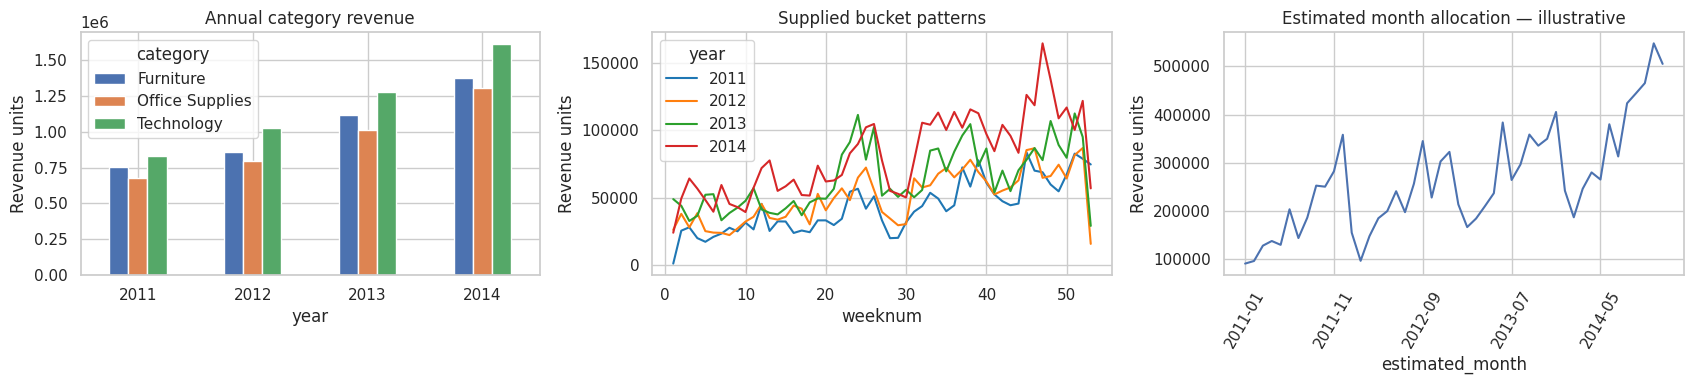

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
annual_category = df.pivot_table(index='year', columns='category', values='sales', aggfunc='sum')
annual_category.plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Annual category revenue')
sns.lineplot(data=weekly, x='weeknum', y='sales', hue='year', palette='tab10', ax=axes[1])
axes[1].set_title('Supplied bucket patterns')
monthly = df.groupby('estimated_month').sales.sum()
monthly.plot(ax=axes[2])
axes[2].set_title('Estimated month allocation — illustrative')
axes[2].tick_params(axis='x', rotation=60)
for ax in axes:
    ax.set_ylabel('Revenue units')
fig.tight_layout()
trend_figure = fig
plt.show()

## 11. SQL analysis inside the notebook
SQLite is included with Python. We create an **in-memory** database from the cleaned data, so no separate database file is required.
A geography join must preserve row count and revenue; duplicate dimension keys can otherwise multiply sales.

In [ ]:
db = sqlite3.connect(':memory:')
geography_cols = ['country', 'region', 'market', 'city', 'state']
geography = df[geography_cols].drop_duplicates().reset_index(drop=True)
geography['geography_id'] = np.arange(len(geography))
fact_sales = df.merge(geography, on=geography_cols, how='left', validate='many_to_one')
customers_dim = df[['customer_id', 'customer_name']].drop_duplicates()
if customers_dim.customer_id.duplicated().any():
    raise ValueError('Customer IDs have conflicting names; resolve before the customer join.')
fact_sales.to_sql('fact_sales', db, index=False, if_exists='replace')
geography.to_sql('dim_geography', db, index=False, if_exists='replace')
customers_dim.to_sql('dim_customer', db, index=False, if_exists='replace')
weekly.to_sql('weekly_sales', db, index=False, if_exists='replace')
join_check = pd.read_sql_query('SELECT COUNT(*) AS rows, SUM(f.sales) AS sales FROM fact_sales f JOIN dim_geography g ON f.geography_id=g.geography_id', db)
assert join_check.iloc[0]['rows'] == len(df)
assert np.isclose(join_check.iloc[0]['sales'], total_sales)
sql_results = {}
print('Database created; geography join reconciled.')

Database created; geography join reconciled.


### SQL: market summary
JOIN attaches market information; GROUP BY and SUM calculate market totals.

In [ ]:
query = """
SELECT g.market, SUM(f.sales) AS revenue, SUM(f.profit) AS profit,
       COUNT(DISTINCT f.order_key) AS orders,
       SUM(f.sales)*1.0/COUNT(DISTINCT f.order_key) AS average_order_value
FROM fact_sales f JOIN dim_geography g ON f.geography_id=g.geography_id
GROUP BY g.market ORDER BY revenue DESC;
"""
sql_results['market_summary'] = pd.read_sql_query(query, db)
display(sql_results['market_summary'].head(10))

,market,revenue,profit,orders,average_order_value
0,APAC,3585833,436000.04900,5437,659.524186
1,EU,2938139,372829.74150,5122,573.631199
2,US,2297354,286397.02170,5009,458.645239
3,LATAM,2164687,221643.48708,5149,420.409206
4,EMEA,806184,43897.97100,2543,317.020842
5,Africa,783776,88871.63100,2289,342.409786
6,Canada,66932,17817.39000,205,326.497561


### SQL: estimated month growth
CTEs build intermediate totals. LAG retrieves the previous total; NULLIF protects division by zero. Dates are estimated.

In [ ]:
query = """
WITH monthly AS (
 SELECT estimated_month, SUM(sales) AS revenue FROM fact_sales GROUP BY estimated_month
), previous AS (
 SELECT *, LAG(revenue) OVER (ORDER BY estimated_month) AS previous_revenue FROM monthly
)
SELECT *, 100.0*(revenue-previous_revenue)/NULLIF(previous_revenue,0) AS mom_growth_pct,
 'Synthetic month allocation; not observed calendar months' AS limitation FROM previous;
"""
sql_results['estimated_month_growth'] = pd.read_sql_query(query, db)
display(sql_results['estimated_month_growth'].head(10))

,estimated_month,revenue,previous_revenue,mom_growth_pct,limitation
0,2011-01,90804,NaN,NaN,Synthetic month allocation; not observed calen...
1,2011-02,96207,90804.0,5.950178,Synthetic month allocation; not observed calen...
2,2011-03,128018,96207.0,33.065162,Synthetic month allocation; not observed calen...
3,2011-04,137678,128018.0,7.545814,Synthetic month allocation; not observed calen...
4,2011-05,129714,137678.0,-5.784512,Synthetic month allocation; not observed calen...
5,2011-06,203510,129714.0,56.891315,Synthetic month allocation; not observed calen...
6,2011-07,143794,203510.0,-29.343030,Synthetic month allocation; not observed calen...
7,2011-08,186246,143794.0,29.522790,Synthetic month allocation; not observed calen...
8,2011-09,252606,186246.0,35.630295,Synthetic month allocation; not observed calen...
9,2011-10,250455,252606.0,-0.851524,Synthetic month allocation; not observed calen...


### SQL: annual category trend
GROUP BY year and category provides the category trend.

In [ ]:
query = """
SELECT year, category, SUM(sales) AS revenue, SUM(profit) AS profit
FROM fact_sales GROUP BY year,category ORDER BY year,category;
"""
sql_results['annual_category_trend'] = pd.read_sql_query(query, db)
display(sql_results['annual_category_trend'].head(10))

,year,category,revenue,profit
0,2011,Furniture,756171,53696.92640
1,2011,Office Supplies,675642,85996.53430
2,2011,Technology,827698,109247.35084
3,2012,Furniture,858913,58132.83400
4,2012,Office Supplies,795113,103305.50780
5,2012,Technology,1023467,145976.93730
6,2013,Furniture,1117739,84062.90050
7,2013,Office Supplies,1010793,149245.73580
8,2013,Technology,1277328,173626.59388
9,2014,Furniture,1378061,89312.06290


### SQL: category product rank
DENSE_RANK ranks products within each category. Ties can return more than five products.

In [ ]:
query = """
WITH products AS (
 SELECT category, product_key, product_name, SUM(sales) AS revenue
 FROM fact_sales GROUP BY category,product_key,product_name
), ranked AS (
 SELECT *, DENSE_RANK() OVER (PARTITION BY category ORDER BY revenue DESC) AS category_rank FROM products
)
SELECT * FROM ranked WHERE category_rank<=5 ORDER BY category,category_rank;
"""
sql_results['category_product_rank'] = pd.read_sql_query(query, db)
display(sql_results['category_product_rank'].head(10))

,category,product_key,product_name,revenue,category_rank
0,Furniture,FUR-CH-10002024|HON 5400 Series Task Chairs fo...,HON 5400 Series Task Chairs for Big and Tall,21870,1
1,Furniture,FUR-CH-10000027|SAFCO Executive Leather Armcha...,"SAFCO Executive Leather Armchair, Black",21329,2
2,Furniture,"FUR-BO-10004679|Safco Library with Doors, Pine","Safco Library with Doors, Pine",17433,3
3,Furniture,FUR-CH-10002247|Hon Executive Leather Armchair...,"Hon Executive Leather Armchair, Adjustable",17122,4
4,Furniture,"FUR-BO-10001934|Bush Library with Doors, Metal","Bush Library with Doors, Metal",17093,5
5,Office Supplies,OFF-BI-10003527|Fellowes PB500 Electric Punch ...,Fellowes PB500 Electric Punch Plastic Comb Bin...,27454,1
6,Office Supplies,"OFF-AP-10004512|Hoover Stove, Red","Hoover Stove, Red",21148,2
7,Office Supplies,OFF-BI-10001359|GBC DocuBind TL300 Electric Bi...,GBC DocuBind TL300 Electric Binding System,19824,3
8,Office Supplies,OFF-BI-10000545|GBC Ibimaster 500 Manual ProCl...,GBC Ibimaster 500 Manual ProClick Binding System,19026,4
9,Office Supplies,"OFF-AP-10002330|Hamilton Beach Stove, Silver","Hamilton Beach Stove, Silver",18248,5


### SQL: above average customers
A subquery calculates the average customer total; HAVING filters above-average customers.

In [ ]:
query = """
SELECT c.customer_id,c.customer_name,SUM(f.sales) AS revenue
FROM fact_sales f JOIN dim_customer c ON f.customer_id=c.customer_id
GROUP BY c.customer_id,c.customer_name
HAVING SUM(f.sales)>(SELECT AVG(total_sales) FROM (
 SELECT SUM(sales) AS total_sales FROM fact_sales GROUP BY customer_id
)) ORDER BY revenue DESC;
"""
sql_results['above_average_customers'] = pd.read_sql_query(query, db)
display(sql_results['above_average_customers'].head(10))

,customer_id,customer_name,revenue
0,SM-203204,Sean Miller,25042
1,TC-209804,Tamara Chand,19050
2,CS-118451,Cari Sayre,16655
3,SP-209202,Susan Pistek,16566
4,VG-218051,Vivek Grady,15654
5,RB-193604,Raymond Buch,15117
6,PF-191201,Peter Fuller,15063
7,TA-213854,Tom Ashbrook,14596
8,BF-110051,Barry Franz,14563
9,AB-101054,Adrian Barton,14476


### SQL: weekly growth
LAG compares consecutive supplied buckets in chronological order.

In [ ]:
query = """
WITH w AS (
 SELECT *, LAG(sales) OVER (ORDER BY period_index) AS previous_sales FROM weekly_sales
)
SELECT year,weeknum,period_index,sales,100.0*(sales-previous_sales)/NULLIF(previous_sales,0) AS growth_pct
FROM w ORDER BY period_index;
"""
sql_results['weekly_growth'] = pd.read_sql_query(query, db)
display(sql_results['weekly_growth'].head(10))

,year,weeknum,period_index,sales,growth_pct
0,2011,1,0,808,NaN
1,2011,2,1,25329,3034.777228
2,2011,3,2,27840,9.913538
3,2011,4,3,19783,-28.940374
4,2011,5,4,17044,-13.845221
5,2011,6,5,20720,21.567707
6,2011,7,6,23130,11.631274
7,2011,8,7,27505,18.914829
8,2011,9,8,24852,-9.645519
9,2011,10,9,31316,26.009979


## 12. Customer segmentation
KMeans groups customers by **Frequency** (composite order count) and **Monetary** value (total Sales).
We log-transform and standardize them before clustering. Recency is omitted because the dates are estimated.
A silhouette score measures cluster separation; it is not prediction accuracy.

,customers,revenue,mean_frequency
value_segment,,,
Higher value,2279,9944495,7.664765
Lower value,799,195818,1.640801
Mid value,1795,2502592,3.885794


Silhouette score: 0.434


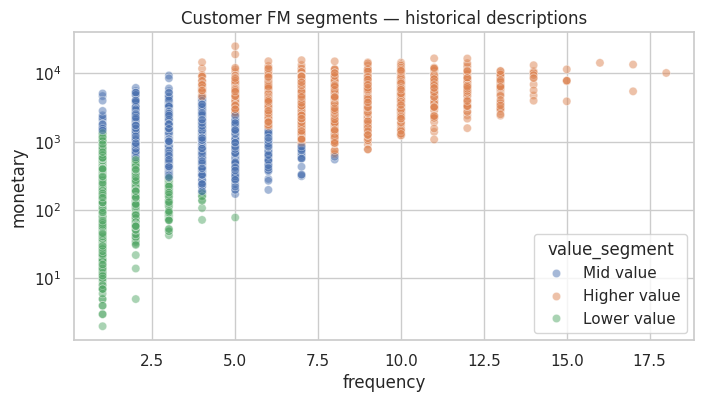

In [ ]:
customer = (df.groupby('customer_id')
            .agg(frequency=('order_key', 'nunique'), monetary=('sales', 'sum'),
                 profit=('profit', 'sum')).reset_index())
cluster_inputs = np.log1p(customer[['frequency', 'monetary']].to_numpy())
cluster_scaler = StandardScaler()
cluster_x = cluster_scaler.fit_transform(cluster_inputs)
kmeans = KMeans(n_clusters=3, n_init=20, random_state=SEED)
customer['cluster'] = kmeans.fit_predict(cluster_x)
cluster_order = customer.groupby('cluster').monetary.mean().sort_values().index
cluster_names = dict(zip(cluster_order, ['Lower value', 'Mid value', 'Higher value']))
customer['value_segment'] = customer.cluster.map(cluster_names)
segment_summary = customer.groupby('value_segment').agg(
    customers=('customer_id', 'size'), revenue=('monetary', 'sum'),
    mean_frequency=('frequency', 'mean'))
silhouette = silhouette_score(cluster_x, customer.cluster,
                              sample_size=min(2000, len(customer)), random_state=SEED)
display(segment_summary)
print('Silhouette score:', round(silhouette, 3))
plt.figure(figsize=(8, 4))
sns.scatterplot(data=customer, x='frequency', y='monetary', hue='value_segment', alpha=0.5)
plt.title('Customer FM segments — historical descriptions')
plt.yscale('log')
plt.show()

## 13. Summarize eight business observations
Every value below is calculated from the current CSV. Suggested actions need further business investigation.
Losses are not deleted, and observed associations do not establish causes.

In [ ]:
top_category = category.revenue.idxmax()
sub_profit = df.groupby('sub_category').profit.sum()
worst_sub = sub_profit.idxmin()
loss_lines = df[df.profit < 0]
high = segment_summary.loc['Higher value']
insights = [
    f"Revenue changed by {(annual.revenue.iloc[-1]/annual.revenue.iloc[0]-1)*100:.1f}% from 2011 to 2014; investigate the growth drivers.",
    f"{top_category} contributes {category.loc[top_category, 'revenue']/total_sales*100:.1f}% of revenue; compare its margin too.",
    f"{regions.index[0]} contributes {regions.iloc[0]/total_sales*100:.1f}% of revenue; investigate regional demand.",
    f"{len(loss_lines):,} lines have negative profit ({len(loss_lines)/len(df)*100:.1f}%); combined profit {loss_lines.profit.sum():,.0f}. Review pricing and costs.",
    f"{worst_sub} has the lowest subcategory profit ({sub_profit.loc[worst_sub]:,.0f}); inspect its product mix.",
    f"Higher-value cluster: {int(high.customers):,} customers and {high.revenue/total_sales*100:.1f}% of revenue; consider retention experiments.",
    f"Discount–Profit correlation: {correlation.loc['discount', 'profit']:.3f}. Association is not causation.",
    f"Supplied buckets 40–53 contribute {df.loc[df.weeknum >= 40, 'sales'].sum()/total_sales*100:.1f}% of sales. This does not verify holiday effects."
]
for number, insight in enumerate(insights, 1):
    print(f'{number}. {insight}\n')

1. Revenue changed by 90.3% from 2011 to 2014; investigate the growth drivers.

2. Technology contributes 37.5% of revenue; compare its margin too.

3. Central contributes 22.3% of revenue; investigate regional demand.

4. 12,544 lines have negative profit (24.5%); combined profit -920,646. Review pricing and costs.

5. Tables has the lowest subcategory profit (-64,083); inspect its product mix.

6. Higher-value cluster: 2,279 customers and 78.7% of revenue; consider retention experiments.

7. Discount–Profit correlation: -0.316. Association is not causation.

8. Supplied buckets 40–53 contribute 34.9% of sales. This does not verify holiday effects.



## 14. Forecasting design — understand before running
We compare Seasonal naive, Linear Regression, Random Forest, XGBoost, LSTM, and ARIMA.

- LSTM reads 26 past steps, each with log revenue plus seasonal sine/cosine features.
- A 13-value context vector adds four seasonal anchors, eight future phase features, and one growth feature.
- A reference forecast uses the corresponding prior-year bucket adjusted by recent 13-bucket growth.
- LSTM and the three tabular models predict **log residuals over that reference**, then convert back to revenue.
- ARIMA models log revenue; seasonal naive repeats last year's corresponding bucket.

The following helper cells contain the model code. Run them once to define the functions; Step 18 actually trains them.
**These are the existing project's modeling choices, made visible in one notebook rather than replaced by a different model.**

In [ ]:
def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)


def features(history, mean, std):
    """Only observed history enters this function; output covers the next 4 buckets."""
    history = np.asarray(history, dtype=float)
    if len(history) < EARLIEST_ORIGIN:
        raise ValueError(f'At least {EARLIEST_ORIGIN} observed buckets required')
    n = len(history)
    log = np.log1p(history)
    past = history[-13:].sum()
    previous = history[-SEASON-13:-SEASON].sum()
    growth = float(np.clip((past+1)/(previous+1), .5, 2.0))
    base = np.log1p(history[n-SEASON:n-SEASON+HORIZON]) + np.log(growth)
    indices = np.arange(n-LOOKBACK,n)
    seq = np.column_stack([(log[-LOOKBACK:]-mean)/std,
                           np.sin(2*np.pi*(indices % SEASON)/SEASON),
                           np.cos(2*np.pi*(indices % SEASON)/SEASON)])
    future_phase = 2*np.pi*(np.arange(n,n+HORIZON) % SEASON)/SEASON
    context = np.r_[(base-mean)/std, np.sin(future_phase), np.cos(future_phase), np.log(growth)]
    lag = [(log[-i]-mean)/std for i in [1,2,4,8,13,26]]
    stats = [(log[-k:].mean()-mean)/std for k in [4,13,26]] + [log[-13:].std()/std]
    flat = np.r_[lag,stats,context]
    return seq.astype('float32'),context.astype('float32'),flat.astype('float32'),base

## 15. Define the LSTM architecture
One 16-unit LSTM summarizes the sequence. Its final output is joined with 13 context values.
A dense layer, ReLU, training-only dropout, and four outputs predict the residuals.
`hidden=16` describes the representation size, not the number of weeks.

In [ ]:
class RevenueLSTM(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(3, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden+13,16),nn.ReLU(),nn.Dropout(.1),nn.Linear(16,HORIZON))

    def forward(self,sequence,context):
        output,_ = self.lstm(sequence)
        return self.head(torch.cat([output[:,-1,:],context],dim=1))



example_model = RevenueLSTM(hidden=16)
print(example_model)
print('Parameters:', sum(p.numel() for p in example_model.parameters()))

RevenueLSTM(
  (lstm): LSTM(3, 16, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=29, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=16, out_features=4, bias=True)
  )
)
Parameters: 1892


## 16. Define how models learn and predict
The training function calculates normalization from its training prefix only.
All four target values of a training window must lie before that prefix's end.
The LSTM uses Adam, gradient clipping, and fixed epochs selected through validation.
It trains on all windows in one batch per epoch. Other algorithms use tabular or time-series inputs.

The prediction function uses only history already observed. A zero residual means use the reference forecast,
not zero revenue. Final values are converted back from log space.

In [ ]:
def train_model(name, y, params=None):
    seed_all()
    params = params or {}
    y=np.asarray(y,dtype=float)
    bundle={'name':name,'params':params,'trained_through_period':len(y)-1,
            'mean':float(np.log1p(y).mean()),'std':float(np.log1p(y).std() or 1),
            'seed':SEED,'training_count':len(y),'lookback':LOOKBACK,'horizon':HORIZON}
    if name=='Seasonal naive':
        return bundle
    if name=='ARIMA':
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            bundle['estimator']=ARIMA(np.log1p(y),order=tuple(params.get('order',[1,1,0]))).fit()
        return bundle
    rows=[features(y[:i],bundle['mean'],bundle['std']) for i in range(EARLIEST_ORIGIN,len(y)-HORIZON+1)]
    if not rows:
        raise ValueError('Insufficient training windows')
    seq=np.array([r[0] for r in rows]);ctx=np.array([r[1] for r in rows]);flat=np.array([r[2] for r in rows])
    target=np.array([np.log1p(y[i:i+HORIZON])-r[3]
                     for i,r in zip(range(EARLIEST_ORIGIN,len(y)-HORIZON+1),rows)],dtype='float32')
    bundle['training_windows']=len(rows)
    if name=='LSTM':
        model=RevenueLSTM(params.get('hidden',16))
        optimizer=torch.optim.Adam(model.parameters(),lr=.003,weight_decay=.01)
        X,C,Y=map(torch.from_numpy,[seq,ctx,target])
        losses=[]
        # Fixed epochs chosen via chronological CV, never by held-out 2014 loss.
        for epoch in range(params.get('epochs',100)):
            model.train();optimizer.zero_grad()
            loss=nn.functional.mse_loss(model(X,C),Y)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
            losses.append(float(loss.detach()))
        bundle['state_dict']={k:v.detach().clone() for k,v in model.state_dict().items()}
        bundle['training_loss']=losses
    else:
        if name=='Linear Regression':
            estimator=LinearRegression()
        elif name=='Random Forest':
            estimator=RandomForestRegressor(n_estimators=150,random_state=SEED,n_jobs=1,**params)
        elif name=='XGBoost':
            estimator=MultiOutputRegressor(XGBRegressor(n_estimators=120,learning_rate=.04,
                objective='reg:squarederror',n_jobs=1,random_state=SEED,**params))
        else:
            raise ValueError(name)
        estimator.fit(flat,target);bundle['estimator']=estimator
    return bundle


def predict(bundle, history):
    y=np.asarray(history,dtype=float)
    if not np.isfinite(y).all() or (y<0).any():
        raise ValueError('History must contain finite nonnegative revenue')
    name=bundle['name']
    if name=='Seasonal naive':
        return y[len(y)-SEASON:len(y)-SEASON+HORIZON].copy()
    if name=='ARIMA':
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            # Refilter the available history with fitted parameters; do not train on test labels.
            fitted=bundle['estimator'].apply(np.log1p(y),refit=False)
            return np.maximum(0,np.expm1(fitted.forecast(HORIZON)))
    seq,ctx,flat,base=features(y,bundle['mean'],bundle['std'])
    if name=='LSTM':
        model=RevenueLSTM(bundle['params'].get('hidden',16))
        model.load_state_dict(bundle['state_dict']);model.eval()
        with torch.no_grad():
            residual=model(torch.from_numpy(seq[None]),torch.from_numpy(ctx[None])).numpy()[0]
    else:
        residual=bundle['estimator'].predict(flat[None])[0]
    # Numerical safeguard only, not an accuracy adjustment. No test-derived clipping.
    return np.maximum(0,np.expm1(np.clip(base+residual,-20,25)))

## 17. Define metrics and rolling evaluation
Lower MAE, RMSE, MAPE and WAPE are better. MAPE excludes zero actuals and reports that count.
Do not call `100 − MAPE` model accuracy.

Evaluation predicts four-bucket blocks. At later origins, newly observed actual history is supplied,
but weights remain fixed. This is **not** one 53-step forecast made at the beginning of 2014.

In [ ]:
def metrics(actual, predicted):
    a,p=np.asarray(actual),np.asarray(predicted)
    e=p-a;mask=a!=0
    return {'MAE':float(np.mean(np.abs(e))), 'RMSE':float(np.sqrt(np.mean(e**2))),
            'MAPE_pct':float(np.mean(np.abs(e[mask]/a[mask]))*100) if mask.any() else None,
            'WAPE_pct':float(np.abs(e).sum()/np.abs(a).sum()*100) if np.abs(a).sum() else None,
            'MAPE_excluded_zero_count':int((~mask).sum()),'n_predictions':len(a)}


def evaluate(bundle,y,start,end):
    """Fixed weights, expanding observed history, non-overlapping four-step blocks."""
    rows=[]
    for origin in range(start,end,HORIZON):
        p=predict(bundle,y[:origin])
        for h in range(min(HORIZON,end-origin)):
            rows.append(dict(model=bundle['name'],origin=origin,horizon=h+1,
                             period_index=origin+h,actual=float(y[origin+h]),prediction=float(p[h])))
    return pd.DataFrame(rows)

## 18. Tune models using the validation periods
Two expanding folds evaluate 2013: train 0–105/evaluate 106–131, then train 0–131/evaluate 132–158.
The complete 2014 period (159–211) remains outside tuning. Small candidate grids keep the exercise manageable.
This step performs real training; runtime depends on your computer.

In [ ]:
CANDIDATES={
 'Seasonal naive':[{}], 'Linear Regression':[{}],
 'Random Forest':[{'max_depth':3,'min_samples_leaf':4},{'max_depth':5,'min_samples_leaf':3}],
 'XGBoost':[{'max_depth':2,'reg_lambda':5},{'max_depth':3,'reg_lambda':10}],
 'LSTM':[{'hidden':16,'epochs':100},{'hidden':32,'epochs':160}],
 'ARIMA':[{'order':[1,1,0]},{'order':[2,1,0]}]}

In [ ]:
folds = [(106, 132), (132, 159)]
chosen = {}
cv_rows = []
cv_best_rows = []
validation_predictions = []
for name, options in CANDIDATES.items():
    candidate_results = []
    for option in options:
        fold_predictions = []
        for start, end in folds:
            fitted = train_model(name, y[:start], option)
            pred = evaluate(fitted, y, start, end)
            fold_predictions.append(pred)
            cv_rows.append({'model': name, 'parameters': json.dumps(option),
                            'train_end': start-1, 'validation_start': start,
                            'validation_end': end-1, **metrics(pred.actual, pred.prediction)})
        pooled = pd.concat(fold_predictions, ignore_index=True)
        score = metrics(pooled.actual, pooled.prediction)
        candidate_results.append((score['RMSE'], option, pooled, score))
    best = min(candidate_results, key=lambda item: item[0])
    chosen[name] = best[1]
    validation_predictions.append(best[2])
    cv_best_rows.append({'model': name, **best[3]})
    print(f'{name}: {best[1]}, validation RMSE = {best[0]:,.2f}', flush=True)

cv_details = pd.DataFrame(cv_rows)
cv_summary = pd.DataFrame(cv_best_rows).sort_values('RMSE').reset_index(drop=True)
selected_model = str(cv_summary.iloc[0]['model'])
display(cv_summary)
print('Selected BEFORE looking at the test:', selected_model)

Seasonal naive: {}, validation RMSE = 19,434.06
Linear Regression: {}, validation RMSE = 35,946.36
Random Forest: {'max_depth': 3, 'min_samples_leaf': 4}, validation RMSE = 16,512.44
XGBoost: {'max_depth': 3, 'reg_lambda': 10}, validation RMSE = 18,585.44
LSTM: {'hidden': 16, 'epochs': 100}, validation RMSE = 18,714.07
ARIMA: {'order': [2, 1, 0]}, validation RMSE = 23,655.75


,model,MAE,RMSE,MAPE_pct,WAPE_pct,MAPE_excluded_zero_count,n_predictions
0,Random Forest,13324.085155,16512.437901,21.391193,20.734162,0,53
1,XGBoost,15171.100562,18585.436453,24.560043,23.608379,0,53
2,LSTM,13935.631706,18714.070333,21.675958,21.685814,0,53
3,Seasonal naive,15358.886792,19434.057860,23.483699,23.900601,0,53
4,ARIMA,17363.793865,23655.753821,28.833591,27.020520,0,53
5,Linear Regression,29187.822899,35946.355600,52.213215,45.420382,0,53


Selected BEFORE looking at the test: Random Forest


## 19. Evaluate on the untouched 2014 test period
Each selected model configuration is trained through 2013 and predicts the same 53 test targets.
The validation selection is frozen. A different test winner is reported honestly without retroactively changing that selection.

Validation selection: Random Forest
Lowest held-out RMSE: XGBoost
API/demo default: LSTM (requested deep learning component)


,model,MAE,RMSE,MAPE_pct,WAPE_pct,MAPE_excluded_zero_count,n_predictions
0,XGBoost,16382.799487,20868.047872,22.838294,20.192560,0,53
1,LSTM,17371.639947,21460.629834,22.519125,21.411352,0,53
2,Random Forest,18435.321234,22968.912607,24.731137,22.722389,0,53
3,ARIMA,17689.916645,23273.787615,22.625151,21.803643,0,53
4,Seasonal naive,21213.301887,26344.506365,26.112183,26.146379,0,53
5,Linear Regression,24085.173039,30586.790862,31.447579,29.686093,0,53


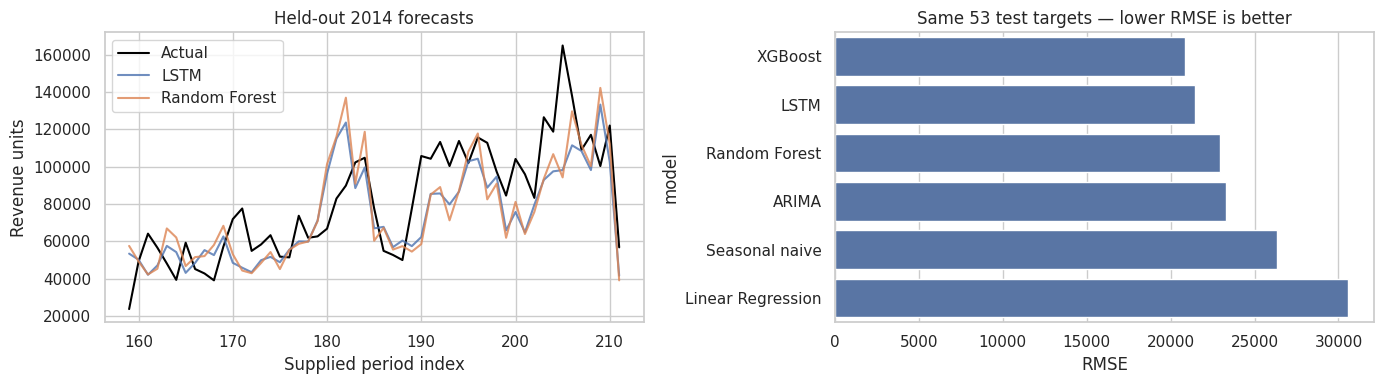

In [ ]:
evaluation_models = {}
test_parts = []
comparison_rows = []
for name in CANDIDATES:
    fitted = train_model(name, y[:159], chosen[name])
    evaluation_models[name] = fitted
    pred = evaluate(fitted, y, 159, len(y))
    test_parts.append(pred)
    comparison_rows.append({'model': name, **metrics(pred.actual, pred.prediction)})
comparison = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
test_predictions = pd.concat(test_parts, ignore_index=True)
display(comparison)
print('Validation selection:', selected_model)
print('Lowest held-out RMSE:', comparison.iloc[0]['model'])
print('API/demo default: LSTM (requested deep learning component)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(np.arange(159, 212), y[159:], color='black', label='Actual')
for name in ['LSTM', selected_model]:
    part = test_predictions[test_predictions.model == name]
    axes[0].plot(part.period_index, part.prediction, label=name, alpha=0.8)
axes[0].set(title='Held-out 2014 forecasts', xlabel='Supplied period index', ylabel='Revenue units')
axes[0].legend()
sns.barplot(data=comparison, y='model', x='RMSE', ax=axes[1])
axes[1].set_title('Same 53 test targets — lower RMSE is better')
fig.tight_layout()
evaluation_figure = fig
plt.show()

## 20. Refit the final models on all available history
Historical evaluation is now complete. Final models use all 212 observations to forecast after 2014.
The evaluation and final models stay separate. The training curve is log-residual MSE, not test RMSE.

Final LSTM windows: 143


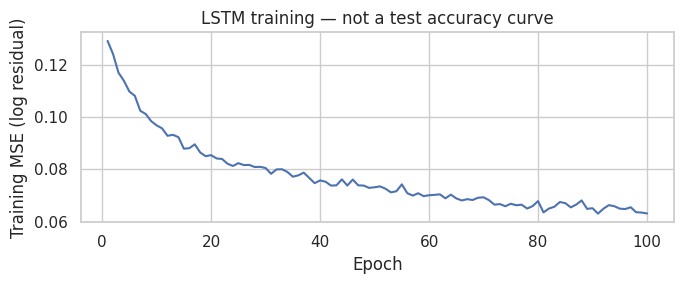

In [ ]:
final_models = {}
for name in CANDIDATES:
    final_models[name] = train_model(name, y, chosen[name])
print('Final LSTM windows:', final_models['LSTM']['training_windows'])
plt.figure(figsize=(7, 3))
plt.plot(np.arange(1, len(final_models['LSTM']['training_loss'])+1),
         final_models['LSTM']['training_loss'])
plt.xlabel('Epoch')
plt.ylabel('Training MSE (log residual)')
plt.title('LSTM training — not a test accuracy curve')
plt.tight_layout()
plt.show()

## 21. Predict the next four buckets
These point forecasts refer to 2015 buckets 1–4 because the history ends in 2014.
No actual 2015 data is supplied, so these predictions cannot yet be scored. No prediction intervals are claimed.
To see another trained model, change `MODEL_TO_USE` to one of the names in the comparison table.

In [ ]:
MODEL_TO_USE = 'LSTM'
future_rows = []
for name, fitted in final_models.items():
    for step, value in enumerate(predict(fitted, y), 1):
        future_rows.append({'model': name, 'year': 2015, 'weeknum': step,
                           'estimated_date': pd.Timestamp('2015-01-01') + pd.Timedelta(days=7*(step-1)),
                           'forecast': float(value), 'dates_are_synthetic': True})
future = pd.DataFrame(future_rows)
forecast_table = future[future.model == MODEL_TO_USE].copy()
display(forecast_table)
print('Next-four total:', round(forecast_table.forecast.sum(), 2))

Next-four total: 250276.2


,model,year,weeknum,estimated_date,forecast,dates_are_synthetic
16,LSTM,2015,1,2015-01-01,41276.685064,True
17,LSTM,2015,2,2015-01-08,62135.315369,True
18,LSTM,2015,3,2015-01-15,73952.737041,True
19,LSTM,2015,4,2015-01-22,72911.462657,True


## 22. Make a simple dashboard
This is generated from the current notebook results. It combines business measures, historical trends,
product and region comparisons, correlations, model errors, and future estimates.

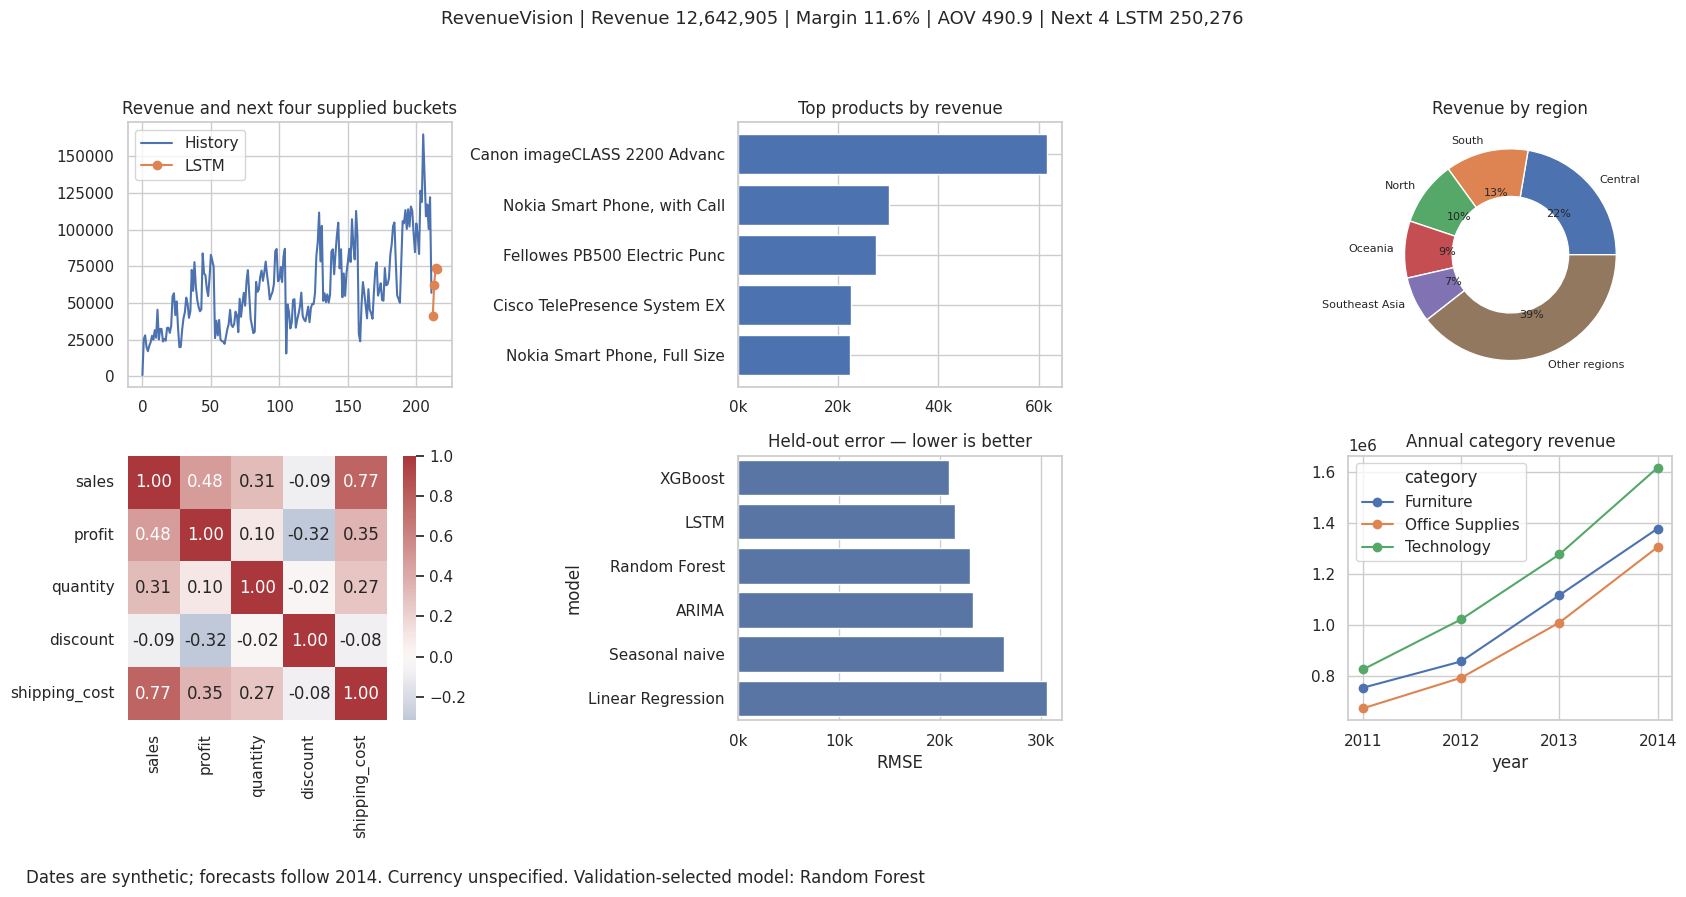

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
fig.suptitle(f"RevenueVision | Revenue {total_sales:,.0f} | Margin {kpis['Profit margin (%)']:.1f}% | "
             f"AOV {kpis['Average order value']:.1f} | Next 4 LSTM {future.loc[future.model=='LSTM', 'forecast'].sum():,.0f}", fontsize=13)
axes[0, 0].plot(np.arange(len(y)), y, label='History')
axes[0, 0].plot(np.arange(212, 216), future.loc[future.model == 'LSTM', 'forecast'], 'o-', label='LSTM')
axes[0, 0].set_title('Revenue and next four supplied buckets')
axes[0, 0].legend()
top_products = (df.groupby(['product_key', 'product_name']).sales.sum()
                .nlargest(5).reset_index())
axes[0, 1].barh(top_products.product_name.str.slice(0, 28), top_products.sales)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title('Top products by revenue')
from matplotlib.ticker import FuncFormatter, MaxNLocator
axes[0, 1].xaxis.set_major_locator(MaxNLocator(4))
axes[0, 1].xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value/1000:.0f}k'))
region_pie = regions.head(5).copy()
if len(regions) > 5:
    region_pie.loc['Other regions'] = regions.iloc[5:].sum()
axes[0, 2].pie(region_pie, labels=region_pie.index, autopct='%1.0f%%',
               wedgeprops={'width': 0.45}, textprops={'fontsize': 8})
axes[0, 2].set_title('Revenue by region')
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[1, 0])
sns.barplot(data=comparison, x='RMSE', y='model', ax=axes[1, 1])
axes[1, 1].set_title('Held-out error — lower is better')
axes[1, 1].xaxis.set_major_locator(MaxNLocator(4))
axes[1, 1].xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value/1000:.0f}k'))
annual_category.plot(ax=axes[1, 2], marker='o')
axes[1, 2].set_title('Annual category revenue')
axes[1, 2].set_xticks(annual_category.index)
fig.text(0.02, 0.01, 'Dates are synthetic; forecasts follow 2014. Currency unspecified. Validation-selected model: ' + selected_model)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
dashboard_figure = fig
plt.show()